# Neural Networks

A neural network is a computational model loosely inspired by the brain. It consists of interconnected units called neurons arranged in layers.

A basic feed-forward neural network has an input layer, hidden layers and an output layer, which makes predictions. Each neuron computes:

$$
out = \sigma(Wx + b)
$$

where $x$ are the inputs, $W$ represents the weights, $b$ is the bias and $\sigma$ is an activation function, such as ReLU, sigmoid, tanh, etc.

The cornerstone of Neural Networks is **Forward Propagation** (data flowing from the input layer to the output layer) and **Backpropagation** (computing weight gradients from the output layer to the input layer).

#### Forward Propagation

Given inputs $x$:
1. Multiply inputs by weights
2. Add bias
3. Apply activation
4. Pass to next layer
5. Repeat until the output layer

For example, for a 3 layer network:

$$
\begin{align}
h_1 & = \sigma(W_1x + b_1) \\
h_2 & = \sigma(W_2h_1 + b_2) \\
\hat{y} & = W_3h_2 + b_3
\end{align}
$$

#### Backpropagation

After forward propagation, the network compares the prediction $\hat{y}$ to the true label $y$ using a loss function (such as MSE for regression or Cross-entropy for classification). Backpropagation computes how the loss changes with respect to each weight, applying the chain rule after each layer of the network, working from the output to the input layer.

The weights are then updated using gradient descent.

#### Mini-batch Stochastic Gradient Descent

Mini-batch SGD is the core optimization technique used to train neural networks. It's a middle ground between two extremes: full-batch gradient descent (use all examples at each training epoch to update the gradients - stable, but slow and memory heavy) and stochastic gradient descent (make updates using a single randomly selected example - very fast, but very unstable).

Mini-batch SGD combines the two by using batches of predetermined size (e.g. 32) picked at random to train the network. This speeds up the training, but also offers greater stability than plain SGD.

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing, load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [23]:
def unbroadcast(grad, shape):
    # sum gradient over broadcasted dimensions so that it matches the given shape.
    # if grad has more dimensions, sum over the extra ones
    while grad.ndim > len(shape):
        grad = grad.sum(axis=0)

    # for each dimension where the original shape was 1,
    # sum over that axis (to collapse the broadcast)
    for i, dim in enumerate(shape):
        if dim == 1:
            grad = grad.sum(axis=i, keepdims=True)

    return grad

# math operations
class Function:
    def __init__(self):
        self.parents = None

    def forward(self, *inputs):
        raise NotImplementedError()

    def backward(self, grad_output):
        raise NotImplementedError()

# basic operations
class Add(Function):
    def forward(self, a, b):
        self.parents = (a, b)
        return a.data + b.data

    def backward(self, grad_output):
        # d(a+b)/da = 1, d(a+b)/db = 1
        a, b = self.parents
        a, b = self.parents
        grad_a = unbroadcast(grad_output, a.data.shape)
        grad_b = unbroadcast(grad_output, b.data.shape)
        return grad_a, grad_b

class Sub(Function):
    def forward(self, a, b):
        self.parents = (a, b)
        return a.data - b.data

    def backward(self, grad_output):
        # d(a-b)/da = 1, d(a-b)/db = -1
        a, b = self.parents
        grad_a = unbroadcast(grad_output, a.data.shape)
        grad_b = unbroadcast(-grad_output, b.data.shape)
        return grad_a, grad_b

class Mul(Function):
    def forward(self, a, b):
        self.parents = (a, b)
        return a.data * b.data

    def backward(self, grad_output):
        # d(a*b)/da = b, d(a*b)/db = a
        a, b = self.parents
        grad_a = unbroadcast(grad_output * b.data, a.data.shape)
        grad_b = unbroadcast(grad_output * a.data, b.data.shape)
        return grad_a, grad_b

class Div(Function):
    def forward(self, a, b):
        self.parents = (a, b)
        return a.data / b.data

    def backward(self, grad_output):
        # d(a/b)/da = 1/b, d(a/b)/db = -a/(b^2)
        a, b = self.parents
        grad_a = unbroadcast(grad_output / b.data, a.data.shape)
        grad_b = unbroadcast(-grad_output * a.data / (b.data ** 2), b.data.shape)
        return grad_a, grad_b

class Pow(Function):
    def forward(self, a, b):
        self.parents = (a, b)
        return np.power(a.data, b.data)

    def backward(self, grad_output):
        # d(a^b)/da = ba^(b-1), d(a^b)/db = a^b * ln(a)
        a, b = self.parents
        grad_a = grad_b = None  
        if a.requires_grad:
            grad_a = grad_output * b.data * np.power(a.data, b.data - 1)
        if b.requires_grad:
            # use safe log for stability
            grad_b = grad_output * np.power(a.data, b.data) * np.log(np.maximum(a.data, 1e-12))
        return grad_a, grad_b

class Neg(Function):
    def forward(self, a):
        self.parents = (a,)
        return -a.data

    def backward(self, grad_output):
        return -grad_output,

class Exp(Function):
    def forward(self, a):
        self.parents = (a,)
        self.out = np.exp(a.data)
        return self.out

    def backward(self, grad_output):
        # d(e^x)/dx = e^x
        return grad_output * self.out,

class Log(Function):
    def forward(self, a):
        self.parents = (a,)
        self.a_data = a.data
        # clamp for numerical stability
        return np.log(np.maximum(a.data, 1e-12))

    def backward(self, grad_output):
        # d(ln(x))/dx = 1/x
        return grad_output / self.a_data,

class Transpose(Function):
    def forward(self, a):
        self.parents = (a,)
        return a.data.T

    def backward(self, grad_output):
        return grad_output.T,

# matrix multiplication
class MatMul(Function):
    def forward(self, a, b):
        self.parents = (a, b)
        return np.matmul(a.data, b.data)

    def backward(self, grad_output):
        a, b = self.parents
        grad_a = np.matmul(grad_output, b.data.T)
        grad_b = np.matmul(a.data.T, grad_output)
        return grad_a, grad_b

# reduction operations
class Sum(Function):
    def __init__(self, axis=None, keepdims=False):
        super().__init__()
        self.axis = axis
        self.keepdims = keepdims

    def forward(self, a):
        self.parents = (a,)
        self.shape = a.data.shape
        return np.sum(a.data, axis=self.axis, keepdims=self.keepdims)

    def backward(self, grad_output):
        a, = self.parents
        grad = np.ones_like(a.data) * grad_output
        if not self.keepdims and self.axis is not None:
            grad = np.broadcast_to(grad, self.shape)
        return (grad,)

class Mean(Function):
    def __init__(self, axis=None, keepdims=False):
        super().__init__()
        self.axis = axis
        self.keepdims = keepdims

    def forward(self, a):
        self.parents = (a,)
        self.shape = a.data.shape
        return np.mean(a.data, axis=self.axis, keepdims=self.keepdims)

    def backward(self, grad_output):
        a, = self.parents
        grad = np.ones_like(a.data) * grad_output / a.data.size
        if not self.keepdims and self.axis is not None:
            grad = np.broadcast_to(grad, self.shape)
        return (grad,)

# activations
class ReLUF(Function):
    def forward(self, a):
        self.parents = (a,)
        self.mask = a.data > 0
        return np.maximum(a.data, 0)

    def backward(self, grad_output):
        return (grad_output * self.mask,)

class SigmoidF(Function):
    def forward(self, a):
        self.parents = (a,)
        out = 1 / (1 + np.exp(-a.data))
        self.out = out  # save for backward
        return out

    def backward(self, grad_output):
        return (grad_output * self.out * (1 - self.out),)

# tensor
class Tensor:
    def __init__(self, data, requires_grad=True) -> None:
        if not isinstance(data, np.ndarray):
            data = np.array(data)
        self.data = data.astype(float)
        self.shape = data.shape
        self.requires_grad = requires_grad
        self.grad = None
        self.grad_fn = None

    def backward(self, grad=None):
        # ensure scalar or user-supplied grad
        if grad is None:
            if self.data.size != 1:
                raise RuntimeError("grad must be specified for non-scalar outputs")
            grad = np.ones_like(self.data)
    
        # initialize gradient of output
        self.grad = grad
    
        # build topological order
        topo_order = []
        visited = set()
        def build_topo(t):
            if t not in visited:
                visited.add(t)
                if t.grad_fn is not None:
                    for p in t.grad_fn.parents:
                        build_topo(p)
                topo_order.append(t)
        build_topo(self)
    
        # propagate backward
        for t in reversed(topo_order):
            if t.grad_fn is not None:
                grads = t.grad_fn.backward(t.grad)
                for parent, grad_input in zip(t.grad_fn.parents, grads):
                    if grad_input is None:
                        continue
                    if parent.grad is None:
                        parent.grad = grad_input
                    else:
                        parent.grad += grad_input

    def item(self):
        return self.data.item()

    def _ensure_tensor(self, other):
        if not isinstance(other, Tensor):
            return Tensor(other)
        return other

    def __add__(self, other):
        other = self._ensure_tensor(other)
        func = Add()
        out_data = func.forward(self, other)
        out = Tensor(out_data, requires_grad=self.requires_grad or other.requires_grad)
        if out.requires_grad:
            out.grad_fn = func
        return out

    __radd__ = __add__

    def __sub__(self, other):
        other = self._ensure_tensor(other)
        func = Sub()
        out_data = func.forward(self, other)
        out = Tensor(out_data, requires_grad=self.requires_grad or other.requires_grad)
        if out.requires_grad:
            out.grad_fn = func
        return out

    def __rsub__(self, other):
        other = self._ensure_tensor(other)
        func = Sub()
        out_data = func.forward(other, self)
        out = Tensor(out_data, requires_grad=self.requires_grad or other.requires_grad)
        if out.requires_grad:
            out.grad_fn = func
        return out

    def __mul__(self, other):
        other = self._ensure_tensor(other)
        func = Mul()
        out_data = func.forward(self, other)
        out = Tensor(out_data, requires_grad=self.requires_grad or other.requires_grad)
        if out.requires_grad:
            out.grad_fn = func
        return out

    __rmul__ = __mul__

    def __truediv__(self, other):
        other = self._ensure_tensor(other)
        func = Div()
        out_data = func.forward(self, other)
        out = Tensor(out_data, requires_grad=self.requires_grad or other.requires_grad)
        if out.requires_grad:
            out.grad_fn = func
        return out

    def __rtruediv__(self, other):
        other = self._ensure_tensor(other)
        func = Div()
        out_data = func.forward(other, self)
        out = Tensor(out_data, requires_grad=self.requires_grad or other.requires_grad)
        if out.requires_grad:
            out.grad_fn = func
        return out

    def __neg__(self):
        func = Neg()
        out_data = func.forward(self)
        out = Tensor(out_data, requires_grad=self.requires_grad)
        if out.requires_grad:
            out.grad_fn = func
        return out

    def __pow__(self, other):
        other = self._ensure_tensor(other)
        func = Pow()
        out_data = func.forward(self, other)
        out = Tensor(out_data, requires_grad=self.requires_grad or other.requires_grad)
        if out.requires_grad:
            out.grad_fn = func
        return out

    def __rpow__(self, other):
        other = self._ensure_tensor(other)
        func = Pow()
        out_data = func.forward(other, self)
        out = Tensor(out_data, requires_grad=self.requires_grad or other.requires_grad)
        if out.requires_grad:
            out.grad_fn = func
        return out

    pow = __pow__

    def __matmul__(self, other):
        other = self._ensure_tensor(other)
        func = MatMul()
        out_data = func.forward(self, other)
        out = Tensor(out_data, requires_grad=self.requires_grad or other.requires_grad)
        if out.requires_grad:
            out.grad_fn = func
        return out

    def __rmatmul__(self, other):
        other = self._ensure_tensor(other)
        func = MatMul()
        out_data = func.forward(other, self)
        out = Tensor(out_data, requires_grad=self.requires_grad or other.requires_grad)
        if out.requires_grad:
            out.grad_fn = func
        return out
        
    def __repr__(self):
        return repr(self.data)

    def mean(self, axis=None, keepdims=False):
        func = Mean(axis, keepdims)
        out_data = func.forward(self)
        out = Tensor(out_data, requires_grad=self.requires_grad)
        if out.requires_grad:
            out.grad_fn = func
        return out

    def sum(self, axis=None, keepdims=False):
        func = Sum(axis, keepdims)
        out_data = func.forward(self)
        out = Tensor(out_data, requires_grad=self.requires_grad)
        if out.requires_grad:
            out.grad_fn = func
        return out

    def exp(self):
        func = Exp()
        out_data = func.forward(self)
        out = Tensor(out_data, requires_grad=self.requires_grad)
        if out.requires_grad:
            out.grad_fn = func
        return out

    def log(self):
        func = Log()
        out_data = func.forward(self)
        out = Tensor(out_data, requires_grad=self.requires_grad)
        if out.requires_grad:
            out.grad_fn = func
        return out

    def relu(self):
        func = ReLUF()
        out_data = func.forward(self)
        out = Tensor(out_data, requires_grad=self.requires_grad)
        if out.requires_grad:
            out.grad_fn = func
        return out

    def sigmoid(self):
        func = SigmoidF()
        out_data = func.forward(self)
        out = Tensor(out_data, requires_grad=self.requires_grad)
        if out.requires_grad:
            out.grad_fn = func
        return out

    @property
    def T(self):
        func = Transpose()
        out_data = func.forward(self)
        out = Tensor(out_data, requires_grad=self.requires_grad)
        if out.requires_grad:
            out.grad_fn = func
        return out

# modules and layers
class Module:
    def parameters(self):
        params = []
        for attr, value in self.__dict__.items():
            if isinstance(value, Tensor) and value.requires_grad:
                params.append(value)
            elif isinstance(value, Module):
                params += value.parameters()
            elif isinstance(value, (list, tuple)):
                for v in value:
                    if isinstance(v, Module):
                        params += v.parameters()
        return params

    def zero_grad(self):
        for p in self.parameters():
            p.grad = None

    def __call__(self, *args, **kwargs):
        return self.forward(*args, **kwargs)

class Linear(Module):
    def __init__(self, in_features, out_features):
        self.W = Tensor(np.random.randn(out_features, in_features) * np.sqrt(2/(in_features+out_features)), requires_grad=True)
        self.b = Tensor(np.zeros((1, out_features)), requires_grad=True)

    def forward(self, x):
        return x @ self.W.T + self.b

class Sequential(Module):
    def __init__(self, *layers):
        self.layers = layers

    def forward(self, x):
        for layer in self.layers:
            x = layer(x)
        return x

    def parameters(self):
        params = []
        for layer in self.layers:
            params += layer.parameters()
        return params

class ReLU(Module):
    def forward(self, x):
        return x.relu()

class Sigmoid(Module):
    def forward(self, x):
        return x.sigmoid()

# losses
def mse_loss(pred, target):
    diff = pred - target
    return (diff * diff).mean()

def binary_cross_entropy(pred, target):
    eps = 1e-12
    pred_clamped = pred.clip(eps, 1 - eps)
    return -(target * pred_clamped.log() + (1 - target) * (1 - pred_clamped).log()).mean()

# optimizers
class SGD:
    def __init__(self, params, lr=0.01):
        self.params = params
        self.lr = lr

    def step(self):
        for p in self.params:
            p.data -= self.lr * p.grad

    def zero_grad(self):
        for p in self.params:
            p.grad = None

In [34]:
def create_mini_batches(X, y, batch_size):
    mini_batches = []
    data = np.hstack((X, y))
    np.random.shuffle(data)
    n_minibatches = data.shape[0] // batch_size
    for i in range(n_minibatches + 1):
        mini_batch = data[i * batch_size:(i + 1) * batch_size, :]
        X_mini = mini_batch[:, :-1]
        Y_mini = mini_batch[:, -1].reshape((-1, 1))
        if len(X_mini) == 0:
            continue
        X_mini = Tensor(X_mini)
        Y_mini = Tensor(Y_mini)
        mini_batches.append((X_mini, Y_mini))
    if data.shape[0] % batch_size != 0:
        mini_batch = data[i * batch_size:]
        X_mini = mini_batch[:, :-1]
        Y_mini = mini_batch[:, -1].reshape((-1, 1))
        if len(X_mini) > 0:
            X_mini = Tensor(X_mini)
            Y_mini = Tensor(Y_mini)
            mini_batches.append((X_mini, Y_mini))
    return mini_batches

In [35]:
data = fetch_california_housing()
X, y = data.data, data.target
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.7, shuffle=True)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
y_train = y_train.reshape(-1, 1)
y_test = y_test.reshape(-1, 1)

X_test = Tensor(X_test)
y_test = Tensor(y_test)

X_train.shape, y_train.shape, X_test.shape, y_test.shape

((14447, 8), (14447, 1), (6193, 8), (6193, 1))

In [25]:
model = Sequential(
    Linear(8, 24),
    ReLU(),
    Linear(24, 12),
    ReLU(),
    Linear(12, 6),
    ReLU(),
    Linear(6, 1)
)
optimizer = SGD(model.parameters(), lr=0.001)

batch_size = 32
n_epochs = 1000
n_samples = X_train.data.shape[0]
history = []

for epoch in range(n_epochs):
    mini_batches = create_mini_batches(X_train, y_train, batch_size)
    losses = []
    for X_mini, y_mini in mini_batches:
        out = model(X_mini)
        loss = mse_loss(out, y_mini)
        losses.append(loss.item())
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    loss = np.mean(losses)
    history.append(loss)
    
    if epoch % 100 == 0:
        print(f"Epoch {epoch}: loss = {loss:.4f}")

Epoch 0: loss = 1.5159
Epoch 100: loss = 0.3182
Epoch 200: loss = 0.2934
Epoch 300: loss = 0.2827
Epoch 400: loss = 0.2731
Epoch 500: loss = 0.2677
Epoch 600: loss = 0.2636
Epoch 700: loss = 0.2605
Epoch 800: loss = 0.2569
Epoch 900: loss = 0.2559


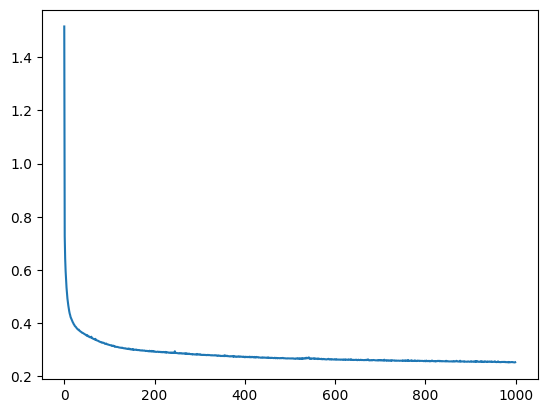

In [26]:
plt.plot(history);

In [36]:
data = load_iris()
X, y = data.data, data.target
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.75, shuffle=True)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
y_train = y_train.reshape(-1, 1)
y_test = y_test.reshape(-1, 1)

X_test = Tensor(X_test)
y_test = Tensor(y_test)

X_train.shape, y_train.shape, X_test.shape, y_test.shape

((112, 4), (112, 1), (38, 4), (38, 1))

In [40]:
model = Sequential(
    Linear(4, 25),
    Sigmoid(),
    Linear(25, 3)
)
optimizer = SGD(model.parameters(), lr=0.001)

batch_size = 4
n_epochs = 1000
n_samples = X_train.data.shape[0]
history = []

for epoch in range(n_epochs):
    mini_batches = create_mini_batches(X_train, y_train, batch_size)
    losses = []
    for X_mini, y_mini in mini_batches:
        out = model(X_mini)
        loss = mse_loss(out, y_mini)
        losses.append(loss.item())
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    loss = np.mean(losses)
    history.append(loss)
    
    if epoch % 100 == 0:
        print(f"Epoch {epoch}: loss = {loss:.4f}")

Epoch 0: loss = 1.0754
Epoch 100: loss = 0.1153
Epoch 200: loss = 0.0755
Epoch 300: loss = 0.0695
Epoch 400: loss = 0.0659
Epoch 500: loss = 0.0633
Epoch 600: loss = 0.0611
Epoch 700: loss = 0.0594
Epoch 800: loss = 0.0579
Epoch 900: loss = 0.0568


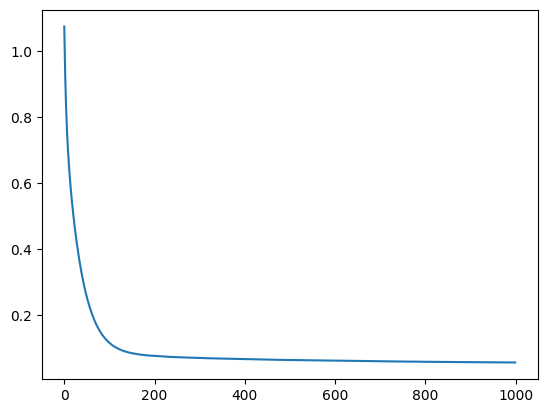

In [41]:
plt.plot(history);